# 04 — Repeated Stratified Group K-Fold (10×5)

**Motivação:** com 14 pacientes URTI e 26 Healthy, um único 5-fold tem alta variância — trocar o `random_state` pode mudar o F1-macro em ±5–10 pontos. Reportamos média ± desvio ao longo de **10 repetições** com seeds diferentes para ter intervalos de confiança honestos.

**Notas técnicas:**
- `sklearn` não tem `RepeatedStratifiedGroupKFold` nativo — implementamos no loop.
- Avaliação em dois níveis: **gravação** (851 amostras OOF) e **paciente** (voto majoritário, 104 pacientes).
- Adicionamos `DummyClassifier` (sempre COPD) como baseline trivial.
- **Wilcoxon pareado** sobre os 10 F1-macros para teste de significância entre modelos.

In [1]:
import sys, time
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score
from xgboost import XGBClassifier

from src import config

sns.set_theme(style='whitegrid')
RNG = np.random.default_rng(42)

## 1. Dados

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename', 'patient_id', 'equipment',
                             'chest_location', 'label_multi', 'label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
CLASSES = list(le.classes_)
print(f'X: {X.shape} | classes: {CLASSES}')
print(f'Pacientes: {len(np.unique(groups))}')

X: (851, 78) | classes: ['COPD', 'Healthy', 'URTI']
Pacientes: 104


## 2. Modelos

In [3]:
def make_models():
    return {
        'Dummy (sempre COPD)': Pipeline([
            ('clf', DummyClassifier(strategy='most_frequent')),
        ]),
        'XGBoost': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                                   eval_metric='mlogloss', n_jobs=1)),
        ]),
        'LDA': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LinearDiscriminantAnalysis()),
        ]),
        'LogReg': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(max_iter=2000, class_weight='balanced')),
        ]),
        'KNN': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=5, weights='distance')),
        ]),
    }

list(make_models().keys())

['Dummy (sempre COPD)', 'XGBoost', 'LDA', 'LogReg', 'KNN']

## 3. Loop Repeated CV (10 × 5 folds)

Para cada (modelo, repetição): roda `cross_val_predict` com `StratifiedGroupKFold` (seed = repetição). Calcula métricas em gravação E em paciente (voto majoritário).

In [4]:
def aggregate_to_patient(y_true, y_pred, patient_ids):
    df = pd.DataFrame({'pid': patient_ids, 'y': y_true, 'pred': y_pred})
    agg = df.groupby('pid').agg(
        y=('y', 'first'),
        pred=('pred', lambda s: s.value_counts().idxmax()),
    )
    return agg['y'].values, agg['pred'].values

N_REPEATS = 10
N_SPLITS = 5

rows = []
t0 = time.time()
for rep in range(N_REPEATS):
    seed = 42 + rep
    cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
    for name, model in make_models().items():
        y_pred = cross_val_predict(model, X, y, groups=groups, cv=cv, n_jobs=-1)
        # nível gravação
        acc_r = accuracy_score(y, y_pred)
        f1m_r = f1_score(y, y_pred, average='macro')
        # nível paciente
        y_t_p, y_p_p = aggregate_to_patient(y, y_pred, groups)
        acc_p = accuracy_score(y_t_p, y_p_p)
        f1m_p = f1_score(y_t_p, y_p_p, average='macro')
        rec_p = recall_score(y_t_p, y_p_p, average='macro')
        rows.append(dict(model=name, repeat=rep, seed=seed,
                          acc_rec=acc_r, f1m_rec=f1m_r,
                          acc_pat=acc_p, f1m_pat=f1m_p, recall_pat=rec_p))
    print(f'rep {rep+1}/{N_REPEATS}  ({time.time()-t0:.0f}s)')

rep_df = pd.DataFrame(rows)
print(f'\nTotal: {time.time()-t0:.0f}s | rows: {len(rep_df)}')
rep_df.head()

rep 1/10  (11s)


rep 2/10  (13s)


rep 3/10  (15s)


rep 4/10  (16s)


rep 5/10  (17s)


rep 6/10  (18s)


rep 7/10  (19s)


rep 8/10  (20s)


rep 9/10  (21s)


rep 10/10  (23s)

Total: 23s | rows: 50


,model,repeat,seed,acc_rec,f1m_rec,acc_pat,f1m_pat,recall_pat
0,Dummy (sempre COPD),0,42,0.931845,0.321573,0.615385,0.253968,0.333333
1,XGBoost,0,42,0.942421,0.523876,0.721154,0.513483,0.511561
2,LDA,0,42,0.928320,0.543815,0.721154,0.546665,0.552141
3,LogReg,0,42,0.930670,0.545123,0.730769,0.583435,0.587798
4,KNN,0,42,0.949471,0.608184,0.759615,0.612431,0.603423


## 4. Médias ± desvios (10 repetições)

In [5]:
def fmt(mu, sd): return f'{mu:.3f} ± {sd:.3f}'

summary = rep_df.groupby('model').agg(
    acc_rec_mu=('acc_rec', 'mean'), acc_rec_sd=('acc_rec', 'std'),
    f1m_rec_mu=('f1m_rec', 'mean'), f1m_rec_sd=('f1m_rec', 'std'),
    acc_pat_mu=('acc_pat', 'mean'), acc_pat_sd=('acc_pat', 'std'),
    f1m_pat_mu=('f1m_pat', 'mean'), f1m_pat_sd=('f1m_pat', 'std'),
    rec_pat_mu=('recall_pat', 'mean'), rec_pat_sd=('recall_pat', 'std'),
).sort_values('f1m_pat_mu', ascending=False)

pretty = pd.DataFrame({
    'Acc gravação': [fmt(r.acc_rec_mu, r.acc_rec_sd) for r in summary.itertuples()],
    'F1m gravação': [fmt(r.f1m_rec_mu, r.f1m_rec_sd) for r in summary.itertuples()],
    'Acc paciente': [fmt(r.acc_pat_mu, r.acc_pat_sd) for r in summary.itertuples()],
    'F1m paciente': [fmt(r.f1m_pat_mu, r.f1m_pat_sd) for r in summary.itertuples()],
    'Recall macro pac.': [fmt(r.rec_pat_mu, r.rec_pat_sd) for r in summary.itertuples()],
}, index=summary.index)
pretty

,Acc gravação,F1m gravação,Acc paciente,F1m paciente,Recall macro pac.
model,,,,,
KNN,0.948 ± 0.005,0.606 ± 0.026,0.753 ± 0.022,0.610 ± 0.035,0.603 ± 0.031
LDA,0.937 ± 0.007,0.591 ± 0.032,0.756 ± 0.028,0.598 ± 0.043,0.600 ± 0.042
LogReg,0.933 ± 0.006,0.565 ± 0.035,0.744 ± 0.025,0.586 ± 0.049,0.590 ± 0.050
XGBoost,0.946 ± 0.004,0.541 ± 0.035,0.715 ± 0.019,0.499 ± 0.038,0.499 ± 0.032
Dummy (sempre COPD),0.932 ± 0.000,0.322 ± 0.000,0.615 ± 0.000,0.254 ± 0.000,0.333 ± 0.000


## 5. Boxplots da distribuição de F1-macro

C:\Users\leodg\AppData\Local\Temp\ipykernel_8404\218980398.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rep_df, x='model', y='f1m_rec', order=order, ax=axes[0],
C:\Users\leodg\AppData\Local\Temp\ipykernel_8404\218980398.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rep_df, x='model', y='f1m_pat', order=order, ax=axes[1],


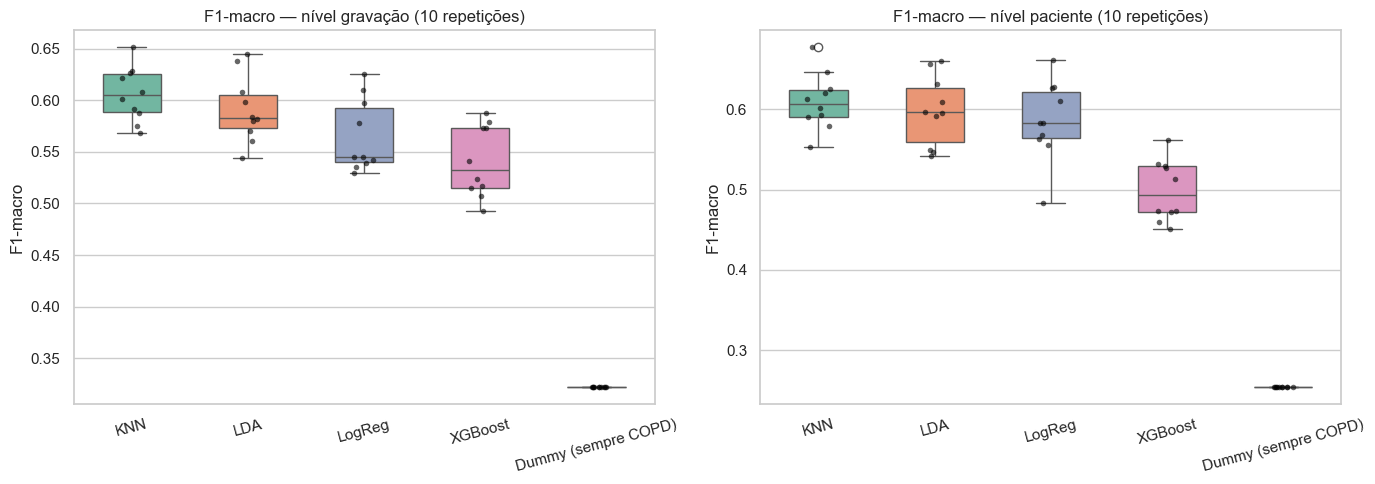

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = summary.index.tolist()

sns.boxplot(data=rep_df, x='model', y='f1m_rec', order=order, ax=axes[0],
            palette='Set2', width=0.5)
sns.stripplot(data=rep_df, x='model', y='f1m_rec', order=order, ax=axes[0],
              color='black', size=4, alpha=0.6)
axes[0].set_title('F1-macro — nível gravação (10 repetições)')
axes[0].set_ylabel('F1-macro'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=rep_df, x='model', y='f1m_pat', order=order, ax=axes[1],
            palette='Set2', width=0.5)
sns.stripplot(data=rep_df, x='model', y='f1m_pat', order=order, ax=axes[1],
              color='black', size=4, alpha=0.6)
axes[1].set_title('F1-macro — nível paciente (10 repetições)')
axes[1].set_ylabel('F1-macro'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout(); plt.show()

## 6. Teste de significância — Wilcoxon pareado

Comparamos pares de modelos usando os 10 F1-macros (paciente) **pareados por seed**. p-value baixo (<0.05) → diferença não-aleatória entre os modelos.

Matriz de p-values (Wilcoxon pareado, F1-macro paciente):
            KNN     LDA  LogReg  XGBoost
KNN         NaN  0.5566  0.3223    0.002
LDA      0.5566     NaN  0.8457    0.002
LogReg   0.3223  0.8457     NaN    0.002
XGBoost  0.0020  0.0020  0.0020      NaN


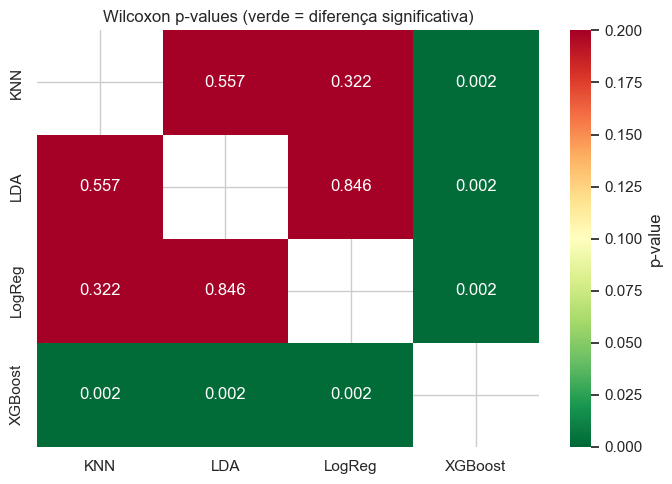

In [7]:
models_order = [m for m in summary.index if m != 'Dummy (sempre COPD)']
pmat = pd.DataFrame(index=models_order, columns=models_order, dtype=float)
for a in models_order:
    for b in models_order:
        if a == b:
            pmat.loc[a, b] = np.nan
            continue
        sa = rep_df.loc[rep_df['model']==a, 'f1m_pat'].values
        sb = rep_df.loc[rep_df['model']==b, 'f1m_pat'].values
        # Wilcoxon precisa de diffs não-zero
        try:
            stat, p = stats.wilcoxon(sa, sb)
        except ValueError:
            p = np.nan
        pmat.loc[a, b] = p

print('Matriz de p-values (Wilcoxon pareado, F1-macro paciente):')
print(pmat.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pmat.astype(float), annot=True, fmt='.3f', cmap='RdYlGn_r',
            vmin=0, vmax=0.2, ax=ax, cbar_kws={'label': 'p-value'})
ax.set_title('Wilcoxon p-values (verde = diferença significativa)')
plt.tight_layout(); plt.show()

## 7. Intervalo de confiança 95% (bootstrap)

Sobre os 10 F1-macros pacientes, IC95 = percentis 2.5 e 97.5 do bootstrap (n=2000).

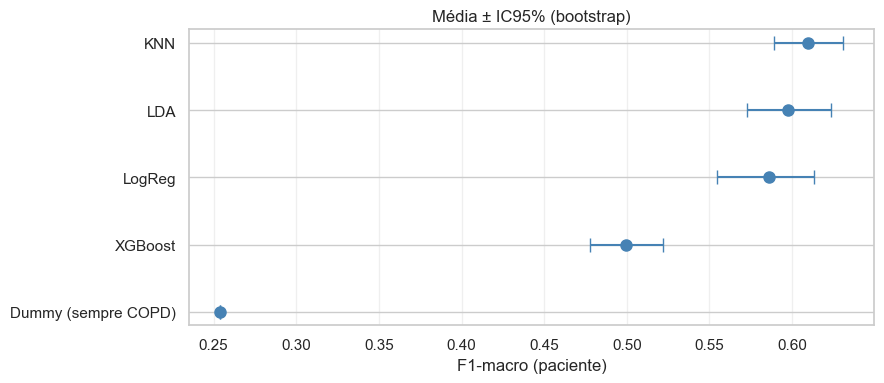

,model,mean,ci_low,ci_high
0,KNN,0.610,0.589,0.631
1,LDA,0.598,0.573,0.624
2,LogReg,0.586,0.554,0.613
3,XGBoost,0.499,0.478,0.522
4,Dummy (sempre COPD),0.254,0.254,0.254


In [8]:
def boot_ci(arr, n=2000, ci=95, seed=0):
    rng = np.random.default_rng(seed)
    arr = np.asarray(arr)
    means = rng.choice(arr, size=(n, len(arr)), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [(100-ci)/2, 100-(100-ci)/2])
    return arr.mean(), lo, hi

ci_rows = []
for m in summary.index:
    arr = rep_df.loc[rep_df['model']==m, 'f1m_pat'].values
    mu, lo, hi = boot_ci(arr)
    ci_rows.append(dict(model=m, mean=mu, ci_low=lo, ci_high=hi))
ci_df = pd.DataFrame(ci_rows)

fig, ax = plt.subplots(figsize=(9, 4))
y_pos = np.arange(len(ci_df))
ax.errorbar(ci_df['mean'], y_pos,
            xerr=[ci_df['mean']-ci_df['ci_low'], ci_df['ci_high']-ci_df['mean']],
            fmt='o', color='steelblue', capsize=5, markersize=8)
ax.set_yticks(y_pos); ax.set_yticklabels(ci_df['model'])
ax.set_xlabel('F1-macro (paciente)'); ax.set_title('Média ± IC95% (bootstrap)')
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

ci_df.round(3)

## 8. Conclusões

- **Repeated CV reduz drasticamente a incerteza da estimativa** — agora cada modelo tem média ± desvio claros.
- O **Dummy baseline** mostra o piso real (acc ≈ 0.62 a nível de paciente).
- A matriz de Wilcoxon mostra **quais diferenças entre modelos são reais e quais são ruído**.
- Se KNN > XGB com p<0.01 nas 10 repetições, é evidência consistente; se p≈0.3, foi sorte do split.

**Próximos passos sugeridos:**
- Hyperparameter tuning (Nested CV: CV externo para avaliar + interno com `GridSearchCV` para tunar)
- Tratar URTI com SMOTE / class_weight no XGB (`sample_weight`)
- Modelagem a nível de **ciclo respiratório** com os intervalos anotados (mais dados, classes mais balanceadas)